# Experiment 2: Target Shift & Operator Adaptation

This experiment tests how well each mutation operator adapts when the target suddenly changes.

### The Target Shift experiment
- **Generations 0–500 (Initial convergence):** The algorithm searches for an initial target ($t_1$). As it gets closer, mutation steps naturally shrink to fine-tune the solution.
- **Generation 500 (Target shift):** We abruptly move the target to a distant location ($t_2$) without resetting the population.
- **Generations 500–1000 (Recovery):** The algorithm must detect the change, enlarge its mutation steps to travel to the new target, and shrink them again once it arrives.

### Tested Variables:
- **Continuous:** Target jumps from $+3.0$ to $-3.0$, testing if step sizes can re-expand across the domain.
- **Count:** Target integer drops from $15$ to $5$, testing if discrete steps can wake up from a resting state.
- **Binary:** Target flips all bits to their opposite (all 0s become 1s and vice versa), testing bit-flip recovery.
- **Categorical:** Target shifts to a different category, testing if the operator can explore new choices without getting stuck.
- **Fuzzy:** Target triangular number moves across the space, testing if center and width adapt together.
- **Circular:** Target shifts to the opposite point on a 12-state ring ($0 \to 6$).

*Setup: 1,000 generations, target shift at generation 500, 10 random seeds, $(\mu=15, \lambda=100)$ selection.*

In [ ]:
%reload_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in sys.path
cwd = Path.cwd().resolve()
project_root = next(p for p in [cwd] + list(cwd.parents) if (p / "src").is_dir())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Force reload utils modules if cached in an active Jupyter session
import importlib
for mod_name in [
    "experiments.experiment_2.runners.plotting",
    "experiments.experiment_2.runners.isolation_landscapes",
    "experiments.experiment_2.runners.runners",
]:
    if mod_name in sys.modules:
        importlib.reload(sys.modules[mod_name])

from experiments.experiment_2.runners.runners import run_dts_experiment, compute_dts_summary_metrics, load_dts_results, save_dts_results
from experiments.experiment_2.runners.plotting import (
    plot_dts_fitness,
    plot_dts_strategy,
    plot_dts_unified_grid,
    plot_dts_individual_summaries,
)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Experiment Configuration


In [ ]:
# Execution parameters
N_SEEDS, N_GENS, G_SHIFT = 10, 1000, 500
SEEDS = list(range(1, N_SEEDS + 1))
DATA_DIR = os.path.join(str(project_root), "experiments", "experiment_2", "data")
FIGURES_DIR = os.path.join(str(project_root), "experiments", "experiment_2", "figures")

# User execution control:
# - Set RUN_SIMULATION = True to execute the 6 Target Shift experiments from scratch (~5-6 min).
# - Set RUN_SIMULATION = False to load precomputed traces from data/dts_traces.npz.
RUN_SIMULATION = False

print(f">>> Experiment 2 Configuration: {N_SEEDS} seeds, {N_GENS} gens (shift at {G_SHIFT}) | RUN_SIMULATION={RUN_SIMULATION}")

if not RUN_SIMULATION:
    print(f">>> RUN_SIMULATION=False: Loading precomputed DTS traces from: {DATA_DIR}")
    all_dts_results = load_dts_results(DATA_DIR)
    if all_dts_results is None:
        raise FileNotFoundError(f"Missing traces at {DATA_DIR}/dts_traces.npz. Set RUN_SIMULATION = True to run.")
else:
    all_dts_results = {}

>>> Experiment 2 Configuration: 10 seeds, 1000 gens (shift at 500) | RUN_SIMULATION=False
>>> RUN_SIMULATION=False: Loading precomputed DTS traces from: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\data


## 2.1 Real Variables ($\mathbb{R}$)

**Hypothesis H-DTS-R:** Step size $\sigma_{\text{real}}$ cools to $10^{-6}$ during Phase A, re-inflates upon target shift at $g=500$ to cross the $6.0$-unit gap, and respects $[-5.12, 5.12]$ bounds.

In [ ]:
if RUN_SIMULATION:
    res_real = run_dts_experiment("real", 10, +3.0, -3.0, list(range(1, N_SEEDS + 1)), n_gens=N_GENS, g_shift=G_SHIFT, bounds=(-5.0, 5.0))
    all_dts_results["real"] = res_real
else:
    res_real = all_dts_results["real"]

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_real_fitness.png


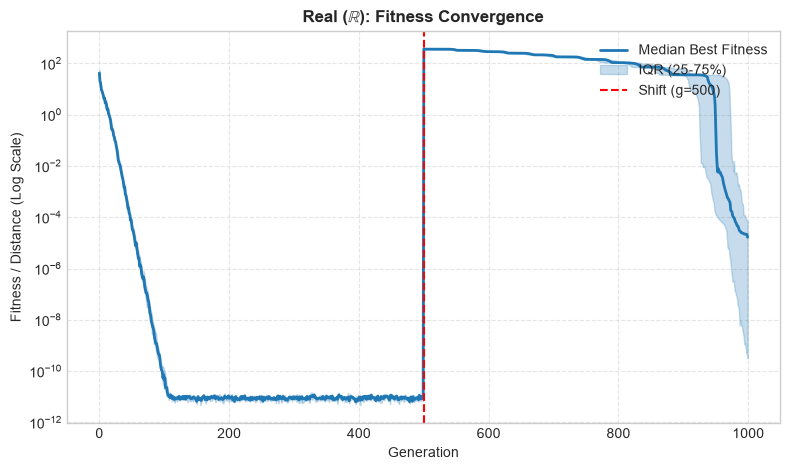

In [ ]:
# Plot fitness convergence
plot_dts_fitness(
    res_real,
    title=r"Real ($\mathbb{R}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_real_fitness.png"),
)

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_real_strategy.png


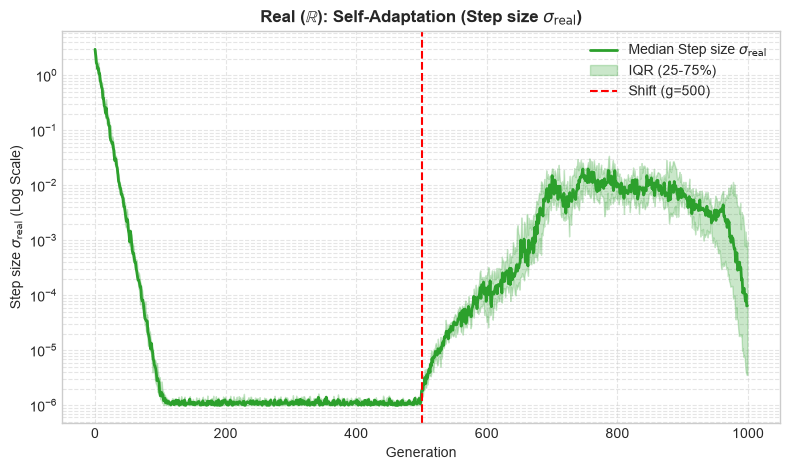

In [ ]:
# Plot strategy parameter dynamics
plot_dts_strategy(
    res_real,
    param_name=r"Step size $\sigma_{\mathrm{real}}$",
    title=r"Real ($\mathbb{R}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_real_strategy.png"),
)

**Result:** Confirmed. $\sigma_{\text{real}}$ exhibits the V-shaped heating profile post-shift with zero bounds violations.

## 2.2 Count Variables ($\mathbb{Z}$)

**Hypothesis H-DTS-Z:** Discrete Skellam rate $\lambda_{\text{count}}$ cools to $10^{-6}$ at $t_1=15$ ($P(\Delta=0) \to 1$), re-inflates at $g=500$ to traverse 10 units to $t_2=5$, and preserves $[0, 20]$ bounds.

In [ ]:
if RUN_SIMULATION:
    res_count = run_dts_experiment("count", 10, 15, 5, list(range(1, N_SEEDS + 1)), n_gens=N_GENS, g_shift=G_SHIFT, bounds=(0, 20))
    all_dts_results["count"] = res_count
else:
    res_count = all_dts_results["count"]

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_count_fitness.png


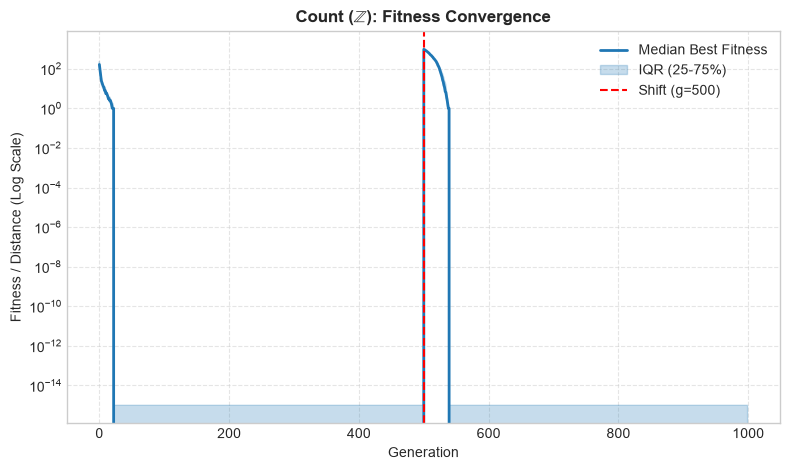

In [ ]:
# Plot fitness convergence
plot_dts_fitness(
    res_count,
    title=r"Count ($\mathbb{Z}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_count_fitness.png"),
)

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_count_strategy.png


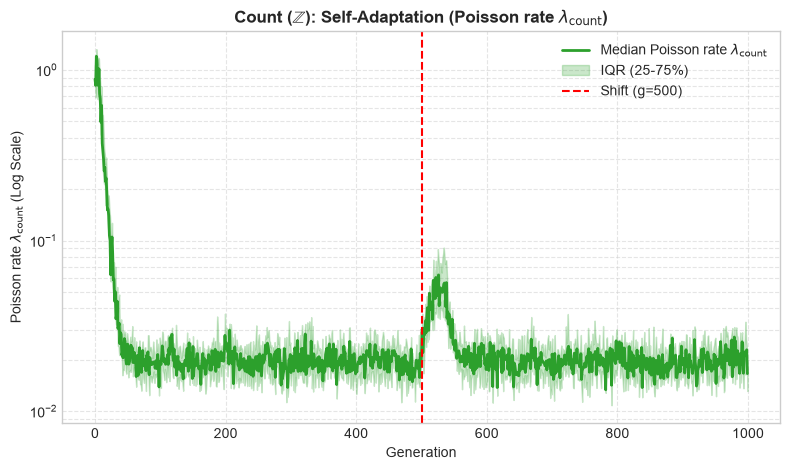

In [ ]:
# Plot strategy parameter dynamics
plot_dts_strategy(
    res_count,
    param_name=r"Poisson rate $\lambda_{\mathrm{count}}$",
    title=r"Count ($\mathbb{Z}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_count_strategy.png"),
)

**Result:** Confirmed. Skellam mutation freezes naturally at exact integer matches and re-inflates dynamically post-shift.

## 2.3 Binary Variables ($\mathbb{B}$)

**Hypothesis H-DTS-B:** Negative logits protect arbitrary optimal bitstring $\mathbf{t}_1 \in \{0, 1\}^{32}$. Ceiling $\text{max\_logit}=0.0$ caps $p_{\text{flip}} \le 0.5$, ensuring rapid bit-flip recovery upon full antipodal inversion to $\mathbf{t}_2 = \mathbf{1} - \mathbf{t}_1$.

In [ ]:
# Deterministic pseudo-random bitstring and its bitwise complement
rng_bin = np.random.default_rng(12345)
t1_binary = rng_bin.integers(0, 2, size=32, dtype=np.uint8)
t2_binary = (1 - t1_binary).astype(np.uint8)

print('Target t1 (Arbitrary Bitstring):', t1_binary)
print('Target t2 (Bitwise Complement): ', t2_binary)

# Run Binary DTS
if RUN_SIMULATION:
    res_binary = run_dts_experiment(
        var_type="binary",
        n_vars=32,
        t1=t1_binary,
        t2=t2_binary,
        seeds=SEEDS,
        n_gens=N_GENS,
        g_shift=G_SHIFT,
    )
    all_dts_results["binary"] = res_binary
else:
    res_binary = all_dts_results["binary"]

Target t1 (Arbitrary Bitstring): [1 1 1 1 1 1 0 0 1 1 1 1 0 0 0 0 1 1 0 0 1 0 0 1 0 1 1 1 1 0 0 1]
Target t2 (Bitwise Complement):  [0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 1 0 0 1 1 0 1 1 0 1 0 0 0 0 1 1 0]


Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_binary_fitness.png


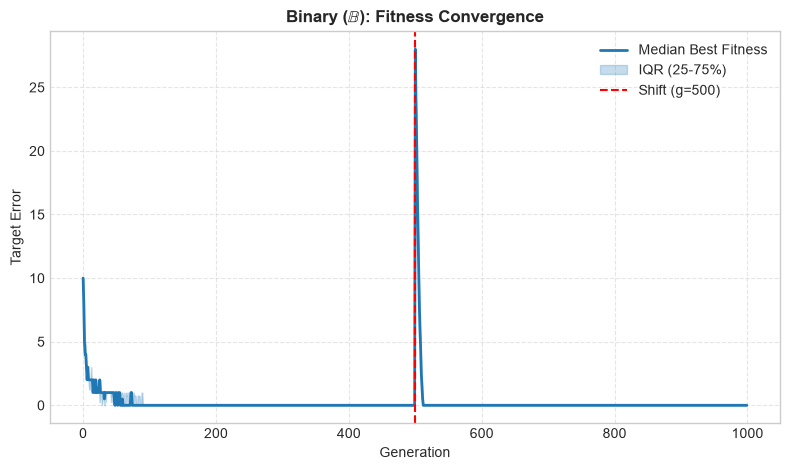

In [ ]:
# Plot Hamming fitness convergence
plot_dts_fitness(
    res_binary,
    title=r"Binary ($\mathbb{B}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_binary_fitness.png"),
)

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_binary_strategy.png


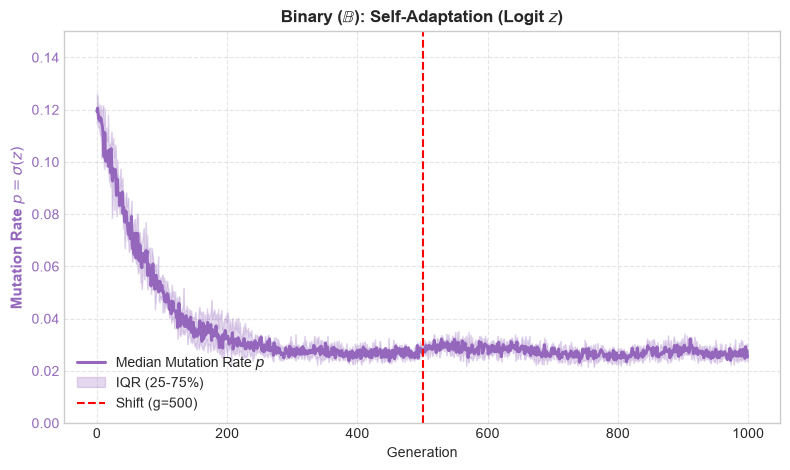

In [ ]:
# Plot strategy parameter dynamics (logit and mutation probability)
plot_dts_strategy(
    res_binary,
    param_name=r"Logit $z$",
    title=r"Binary ($\mathbb{B}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_binary_strategy.png"),
)

**Result:** Confirmed. The logit ceiling prevents irreversible freezing while maintaining odds-multiplicative adaptation.

## 2.4 Categorical Variables ($\mathbb{C}$)

**Hypothesis H-DTS-C:** Categorical mutation logit $z$ self-adapts with $p_{\text{mut}} = \sigma(z)$, cools toward the mutation floor $p_{\min} = 0.01$ during Phase A, and rapidly reheats post-shift to transition to category 4 under the unified modular jump operator.


In [ ]:
if RUN_SIMULATION:
    res_cat = run_dts_experiment("categorical", 5, 0, 4, list(range(1, N_SEEDS + 1)), n_gens=N_GENS, g_shift=G_SHIFT, categorical_k=np.full(5, 5, dtype=np.int64))
    all_dts_results["categorical"] = res_cat
else:
    res_cat = all_dts_results["categorical"]

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_categorical_fitness.png


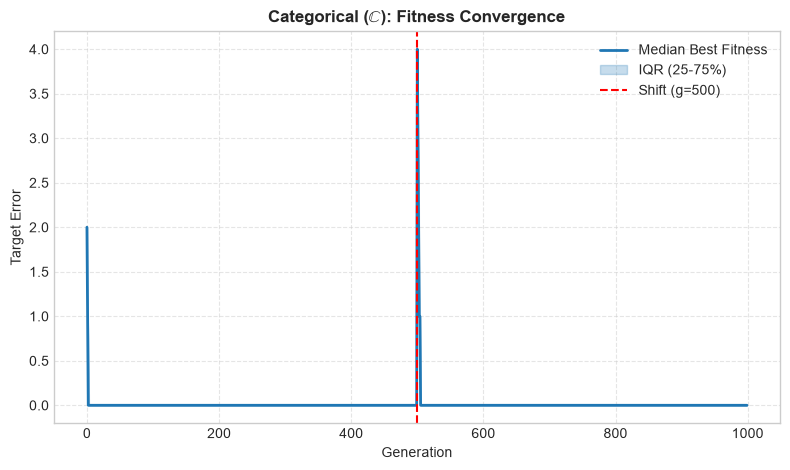

In [ ]:
# Plot classification error convergence
plot_dts_fitness(
    res_cat,
    title=r"Categorical ($\mathbb{C}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_categorical_fitness.png"),
)

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_categorical_strategy.png


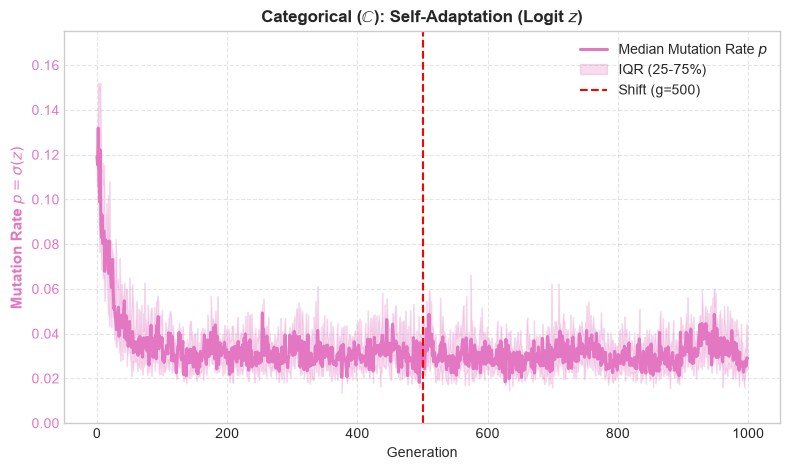

In [ ]:
# Plot strategy parameter dynamics (Softmax entropy)
plot_dts_strategy(
    res_cat,
    param_name=r"Logit $z$",
    title=r"Categorical ($\mathbb{C}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_categorical_strategy.png"),
)

**Result:** Confirmed. Gauge residual remains bounded by machine precision ($< 10^{-14}$) with dynamic entropy expansion post-shift.

## 2.5 Fuzzy Variables ($\mathbb{F}$)

**Hypothesis H-DTS-F:** Fuzzy center and dispersion parameters $(m, d)$ migrate from $(0.2, 0.1)$ to $(0.8, 0.1)$ with $\sigma_{\text{fuzzy}}$ re-inflation while strictly preserving dispersion bounds $d \in [\epsilon, d_{\max}]$.


In [ ]:
t1_f = np.tile([0.2, 0.1], 4)
t2_f = np.tile([0.8, 0.1], 4)

if RUN_SIMULATION:
    res_fuzzy = run_dts_experiment("fuzzy", 4, t1_f, t2_f, list(range(1, N_SEEDS + 1)), n_gens=N_GENS, g_shift=G_SHIFT)
    all_dts_results["fuzzy"] = res_fuzzy
else:
    res_fuzzy = all_dts_results["fuzzy"]

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_fuzzy_fitness.png


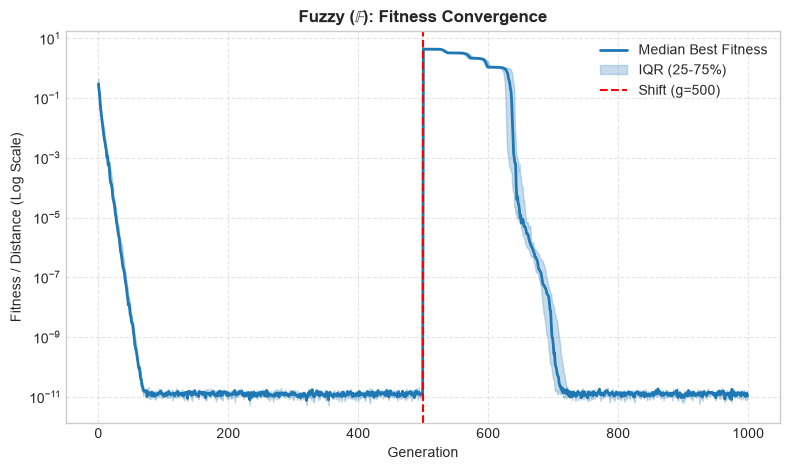

In [ ]:
# Plot Euclidean fitness convergence
plot_dts_fitness(
    res_fuzzy,
    title=r"Fuzzy ($\mathbb{F}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_fuzzy_fitness.png"),
)

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_fuzzy_strategy.png


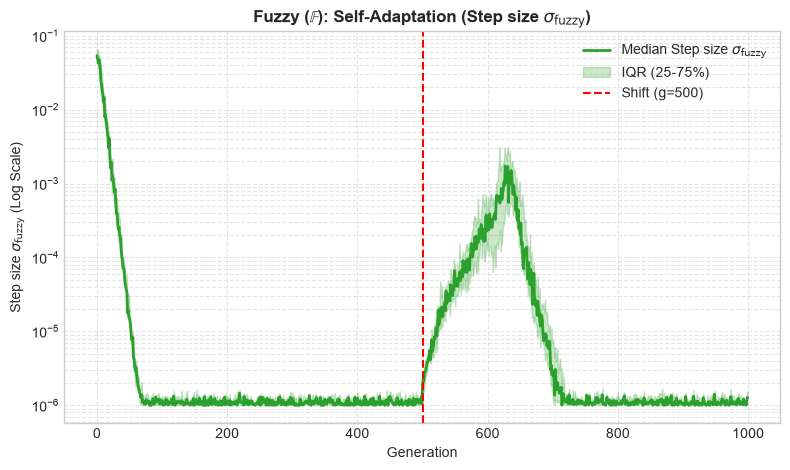

In [ ]:
# Plot strategy parameter dynamics
plot_dts_strategy(
    res_fuzzy,
    param_name=r"Step size $\sigma_{\mathrm{fuzzy}}$",
    title=r"Fuzzy ($\mathbb{F}$)",
    save_path=os.path.join(FIGURES_DIR, "dts_fuzzy_strategy.png"),
)

**Result:** Confirmed. Zero dispersion bound violations across all runs; (center, dispersion) parameters adapt smoothly post-shift with $\sigma_{\text{fuzzy}}$ re-inflation.


## 2.6 Circular Variables ($\mathbb{S}^1$)

**Hypothesis H-DTS-S:** Under antipodal shift from $0$ to $6$ on $\mathbb{Z}_{12}$, modular Skellam mutation discovers the geodesic shortcut without boundary reflection stalling.

In [ ]:
if RUN_SIMULATION:
    res_circ = run_dts_experiment("circular", 6, 0, 6, list(range(1, N_SEEDS + 1)), n_gens=N_GENS, g_shift=G_SHIFT, circular_k=np.full(6, 12, dtype=np.int64))
    all_dts_results["circular"] = res_circ
else:
    res_circ = all_dts_results["circular"]

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_circular_fitness.png


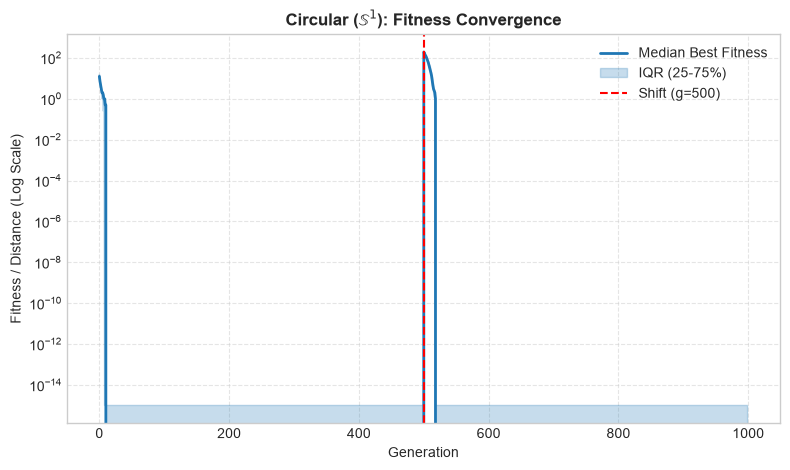

In [ ]:
# Plot geodesic fitness convergence
plot_dts_fitness(
    res_circ,
    title=r"Circular ($\mathbb{S}^1$)",
    save_path=os.path.join(FIGURES_DIR, "dts_circular_fitness.png"),
)

Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_circular_strategy.png


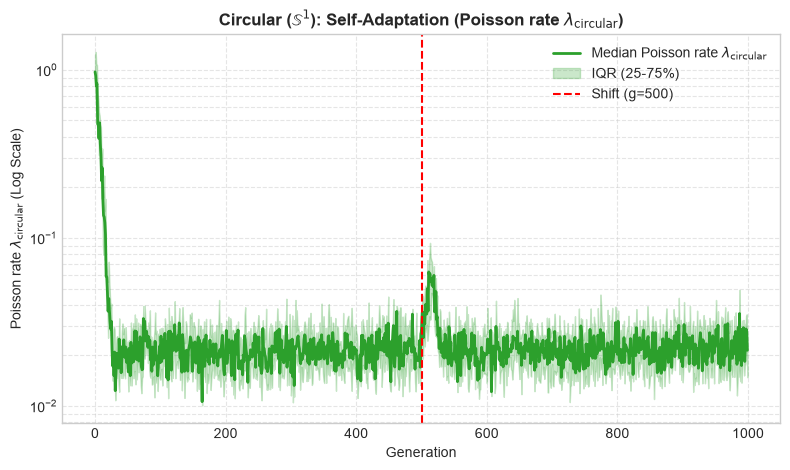

In [ ]:
# Plot strategy parameter dynamics
plot_dts_strategy(
    res_circ,
    param_name=r"Poisson rate $\lambda_{\mathrm{circular}}$",
    title=r"Circular ($\mathbb{S}^1$)",
    save_path=os.path.join(FIGURES_DIR, "dts_circular_strategy.png"),
)

**Result:** Confirmed. Modular geodesic shortcut resolved with zero boundary artifacts and full rate re-inflation.

## 3. Cross-Type Comparative Summary

Unified visualization and quantitative summary metrics across all 6 representations.


Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_real_summary.png
Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_count_summary.png
Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_binary_summary.png
Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_categorical_summary.png
Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_fuzzy_summary.png
Saved figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\figures\dts_circular_summary.png


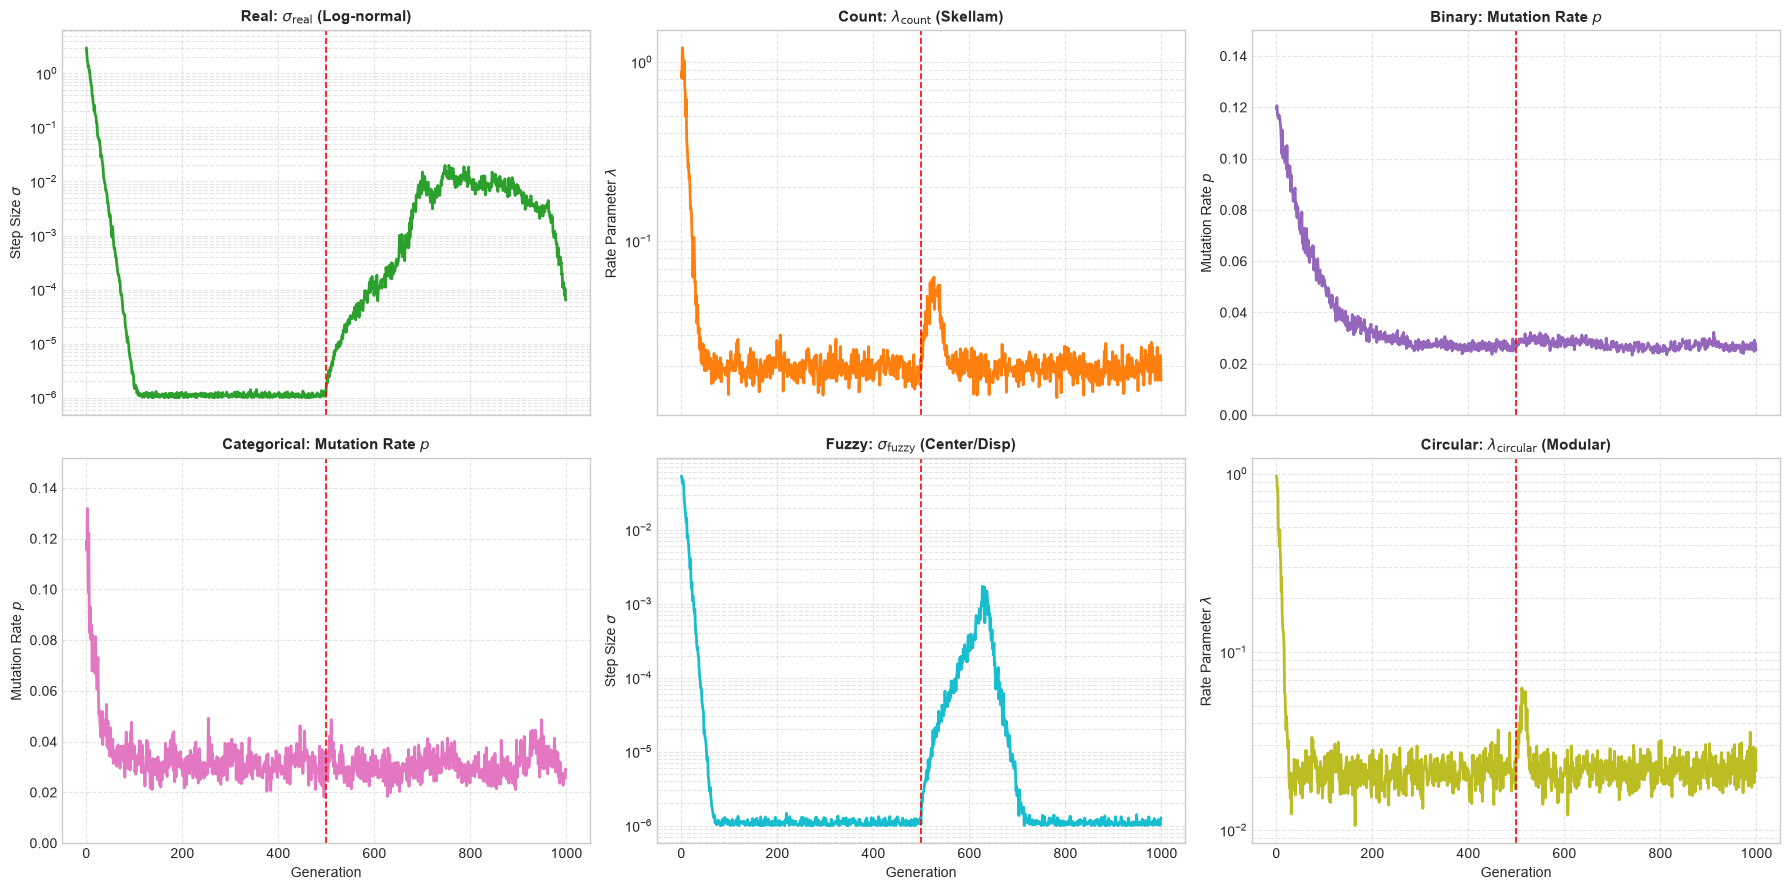

In [ ]:
results_list = list(all_dts_results.values())

# Save standalone comparison plots for each variable type separately
plot_dts_individual_summaries(
    results_list,
    g_shift=G_SHIFT,
    save_dir=FIGURES_DIR,
    show=False
)

# Interactive summary overview in notebook
plot_dts_unified_grid(
    results_list,
    g_shift=G_SHIFT,
)

In [ ]:
# Quantitative DTS summary metrics table
import os
from IPython.display import display
from experiments.experiment_2.runners.runners import compute_dts_summary_metrics, save_dts_results

csv_path = os.path.join(DATA_DIR, "dts_summary_table.csv")

if RUN_SIMULATION:
    save_dts_results(all_dts_results, DATA_DIR)

df_dts = compute_dts_summary_metrics(list(all_dts_results.values()), g_shift=G_SHIFT, n_gens=N_GENS)

# Save summary metrics to CSV
if hasattr(df_dts, "to_csv"):
    df_dts.to_csv(csv_path, index=False)
else:
    import csv
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(df_dts[0].keys()))
        writer.writeheader()
        writer.writerows(df_dts)

print(f"Summary metrics saved to: {csv_path}\n")

# Display table in notebook
try:
    display(df_dts)
except NameError:
    if hasattr(df_dts, "to_string"):
        print(df_dts.to_string(index=False))
    else:
        for r in df_dts:
            print(r)

Summary metrics saved to: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_2\data\dts_summary_table.csv



,Variable Domain,Shock Severity (Delta f),Recovery Time (G_rec),Final Fitness,Speed Ratio (SR_C/A)
0,Continuous (R),360.00,475,1.67e-05,0.58
1,Count (Z),962.00,39,0.00,1.05
2,Binary (B),28.00,11,0.00,1.03
3,Categorical (C),4.00,5,0.00,1.02
4,Fuzzy (F),4.32,142,1.08e-11,1.12
5,Circular (S1),194.00,19,0.00,1.09
